# Assignment 7: The Pacific Decadal Oscillation with PCA

In the Week 7 tutorial, PCA applied to tropical Pacific sea surface temperature (SST) found El Niño on its own. This assignment asks you to do the same thing for a different and slower pattern, the **Pacific Decadal Oscillation** (PDO), in the North Pacific.

You do not need a climate background for this. Here is everything you need to know about the PDO. It is a pattern of sea surface temperature in the North Pacific that switches sign every few decades. In its positive phase the water along the west coast of North America is warmer than normal and the central North Pacific is cooler than normal. In its negative phase the pattern is reversed. It matters because it shifts rainfall over the western United States and the productivity of Pacific fisheries for years at a time. It was discovered in 1997 by a group studying salmon catches, and they defined it exactly the way you will compute it: **the first principal component of North Pacific SST anomalies, after the global mean SST anomaly has been removed.**

That last step is the point of the assignment. You will run PCA twice, once without removing the global mean and once with, and see what changes. Along the way you will test your result against the official index, relate it to the ENSO index from the tutorial, and check whether the pattern holds up on years it was not fitted to.

You may reuse code from the tutorial, including the `to_matrix` and `to_map` helpers. Keep written answers short: two or three sentences is enough.

**Data.** The same NOAA ERSST v5 monthly SST field as the tutorial, read over the network. The cells below load the global field for 1950 to 2024.

_I used Google Gemini to support with code debugging, to explain any computational or data concepts I was missing, and to provide guiding questions to help me find solutions myself, in line with the Socratic mode method described on the course website._

In [1]:
import numpy as np
import pandas as pd
import xarray as xr
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA

In [2]:
DATA = "/data9/CLMT5120/data/shr/sst.mnmean.nc"     # NOAA ERSST v5, copied to the class server
sst = xr.open_dataset(DATA)["sst"].sel(time=slice("1950", "2024")).load()
print(sst.shape, "= (months, latitudes, longitudes)")

(900, 89, 180) = (months, latitudes, longitudes)


## Part 1: Anomalies and the North Pacific

1) Compute monthly SST anomalies for the whole globe by subtracting, from each month, the 1950 to 2024 mean for that calendar month. Then select the North Pacific, **20N to 70N and 120E to 260E**, and plot the anomaly map for **January 2015**. This was the peak of a famous marine heat wave, so the map should show a large warm patch.

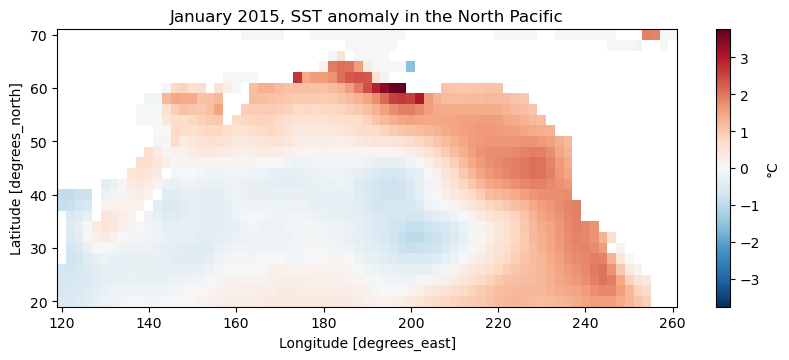

In [3]:
clim = sst.sel(time=slice("1950", "2024")).groupby("time.month").mean("time")
anom = sst.groupby("time.month") - clim    

north_pacific = anom.sel(lat=slice(70,20), lon=slice(120,260))

fig, ax = plt.subplots(figsize=(10, 3.6))
north_pacific.sel(time="2015-1").squeeze().plot(ax=ax, cmap="RdBu_r", cbar_kwargs={"label": "°C"})
ax.set_title("January 2015, SST anomaly in the North Pacific")
plt.show()

2) Turn the North Pacific anomaly field into a matrix of months by ocean grid cells, with the land cells dropped and each cell weighted by the square root of the cosine of its latitude. Report the shape and the number of land cells dropped. Also write the function that puts a vector back on the map, since you will need it for every EOF plot.

In [4]:
weight = np.sqrt(np.cos(np.deg2rad(north_pacific.lat))) # area weight, one value per latitude

def to_matrix(field):
    # (months, lat, lon) DataArray -> (months, ocean cells) array, plus the ocean mask
    flat = (field * weight).values.reshape(field.shape[0], -1)
    ocean = ~np.isnan(flat[0])
    return flat[:, ocean], ocean

def to_map(vector, ocean, field=north_pacific):
    # one row of the matrix back onto the grid, NaN over land, as a DataArray with coordinates
    full = np.full(ocean.size, np.nan)
    full[ocean] = vector
    return xr.DataArray(full.reshape(field.shape[1:]), coords={"lat": field.lat, "lon": field.lon}) / weight

X_anom, ocean = to_matrix(north_pacific)
print("matrix:", X_anom.shape, "= (months, ocean cells);", (~ocean).sum(), "land cells dropped")

matrix: (900, 1231) = (months, ocean cells); 615 land cells dropped


## Part 2: First attempt, straight from the anomalies

3) Fit a PCA with 10 components on this matrix. Print the fraction of variance explained by the first four components, plot the first EOF as a map, and plot the first PC as a time series with a 12-month running mean on top of it.

variance explained by the first four patterns of the SST anomaly: [0.2183 0.1896 0.0859 0.0632]
variance explained by PC1: 0.2183
variance explained by PC2: 0.1896
variance explained by PC3: 0.0859
variance explained by PC4: 0.0632


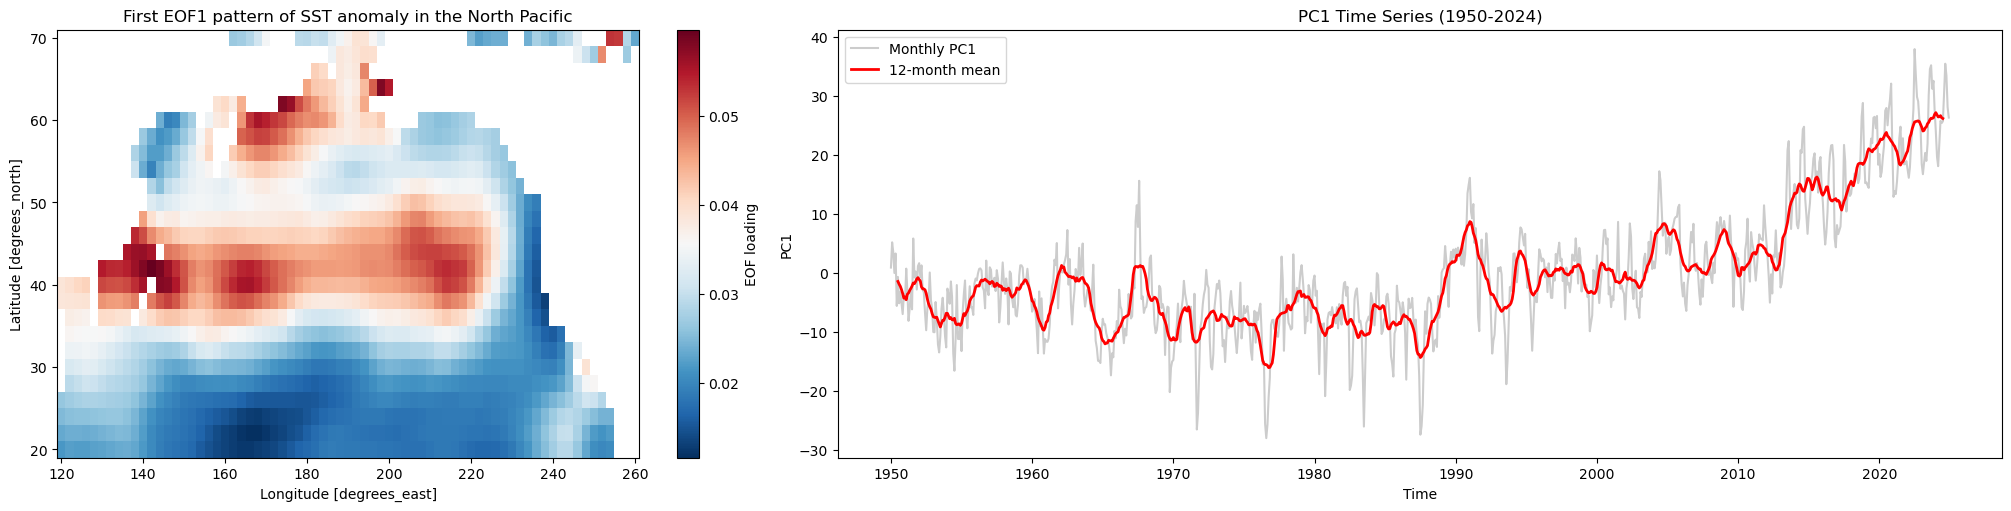

In [5]:
pca = PCA(n_components=10).fit(X_anom)
pcs = pca.transform(X_anom)
variance_explained = np.round(pca.explained_variance_ratio_[:4], 4)
print("variance explained by the first four patterns of the SST anomaly:", variance_explained)
print("variance explained by PC1:", variance_explained[0])
print("variance explained by PC2:", variance_explained[1])
print("variance explained by PC3:", variance_explained[2])
print("variance explained by PC4:", variance_explained[3])

#fig, axes = plt.subplots(1, 2, figsize=(14, 3.4), gridspec_kw={"width_ratios": [1.4, 1]})
fig, axes = plt.subplots(1, 2,figsize=(20, 5), gridspec_kw={"width_ratios": [1, 2]}, layout="constrained")
to_map(pca.components_[0], ocean).plot(ax=axes[0], cmap="RdBu_r", cbar_kwargs={"label": "EOF loading"})
axes[0].set_title("First EOF1 pattern of SST anomaly in the North Pacific")

pc1 = pcs[:,0]
pc1_series = pd.Series(pc1, index=north_pacific.time.values)
pc1_12month = pc1_series.rolling(window=12, center=True).mean()

axes[1].plot(north_pacific.time, pcs[:, 0], label="Monthly PC1", alpha=0.4, color="gray")
axes[1].plot(north_pacific.time, pc1_12month, label="12-month mean", color="red", linewidth=2)

axes[1].set_title("PC1 Time Series (1950-2024)")
axes[1].set_ylabel("PC1")
axes[1].set_xlabel("Time")
axes[1].legend()

plt.show()

p4) Compute the correlation between PC1 and time (a simple counter, `np.arange(len(pc1))`, will do). Then look at the variance explained by the first and second components. When two components explain almost the same fraction of the variance, PCA cannot separate them reliably, and each pattern is a mixture of the two. Is that the case here? Answer with the two numbers.

In [6]:
time_counter = np.arange(len(pc1))
corr = np.corrcoef(pc1, time_counter)[0,1]
print(f"Correlation between PC1 and time: {corr:.3f}")

Correlation between PC1 and time: 0.661


_The correlation between PC1 and time is 0.661. In #3, I found that the variance explained by PC1 is 0.2183 and the variance explained by PC2 is 0.1896. PC1 explains 21.83% of the variance and PC2 explain 18.96% of the variance. Yes, the first two components explain almost the same fraction of the variance, so each pattern is a mixture of the two. Since the variance fractions (0.2183 and 0.1896) are very close (with a difference of only ~0.03), sampling error prevents the PCA from separating the two EOF modes, so PC1 and PC2 appear to be a mixture of climate variability and the global warming trend._

## Part 3: Remove the global mean

5) Compute the global mean SST anomaly for each month, weighted by the cosine of latitude so that each grid cell counts in proportion to its area, and plot it. xarray's `weighted` method does this: `anom.weighted(np.cos(np.deg2rad(anom.lat))).mean(["lat", "lon"])`.

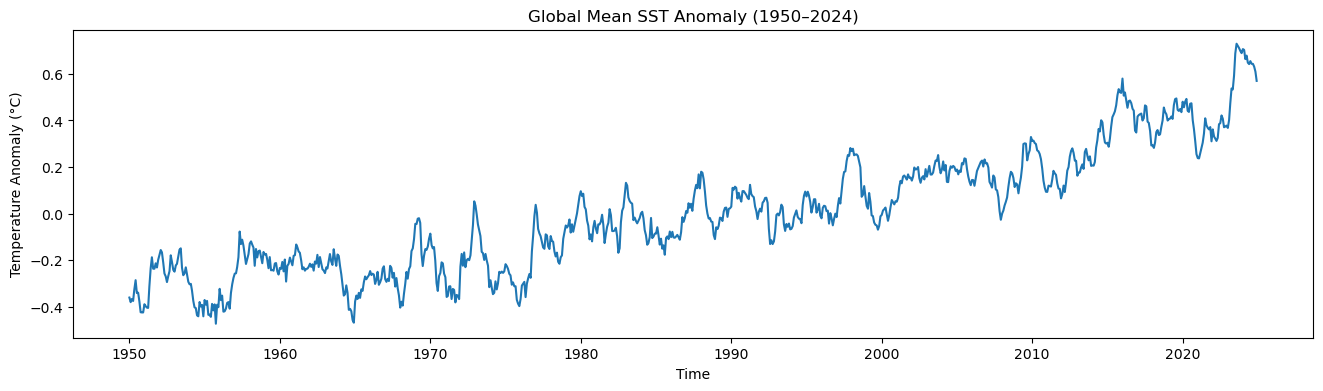

In [7]:
global_mean_anom = anom.weighted(np.cos(np.deg2rad(anom.lat))).mean(["lat", "lon"])

fig, ax = plt.subplots(figsize=(16, 4))
global_mean_anom.plot(ax=ax)
ax.set_title("Global Mean SST Anomaly (1950–2024)")
ax.set_ylabel("Temperature Anomaly (°C)")
ax.set_xlabel("Time")
plt.show()

6) Subtract the global mean anomaly from every grid cell of the North Pacific anomalies, build the matrix again, fit a new PCA with 10 components, and repeat the plots from question 3: the variance explained by the first four components, the EOF 1 map, and PC1 with its 12-month running mean.

matrix: (900, 1231) = (months, ocean cells); 615 land cells dropped
variance explained by the first four patterns of the SST anomaly: [0.2249 0.1268 0.074  0.0657]
variance explained by PC1: 0.2249
variance explained by PC2: 0.1268
variance explained by PC3: 0.074
variance explained by PC4: 0.0657


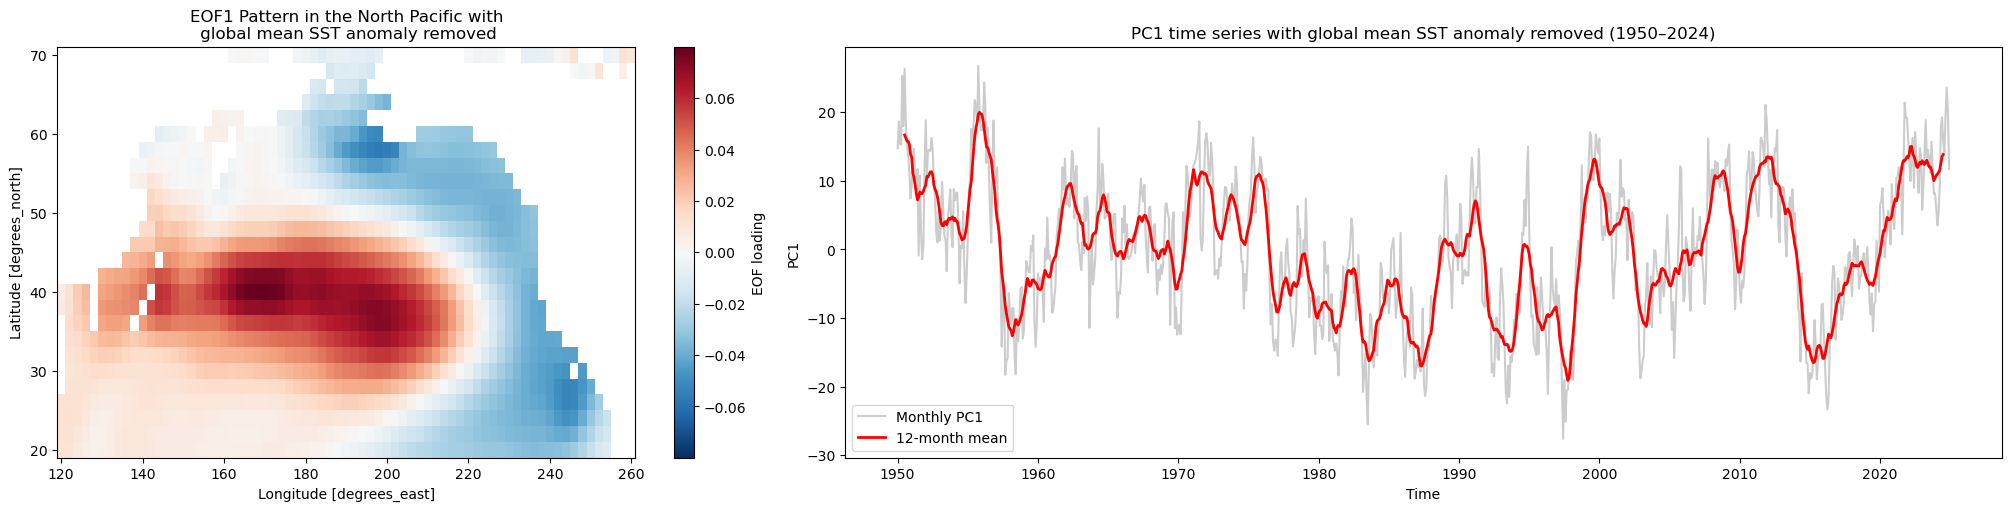

In [8]:
north_pacific_new = north_pacific - global_mean_anom

X_anom_new, ocean_new = to_matrix(north_pacific_new)
print("matrix:", X_anom_new.shape, "= (months, ocean cells);", (~ocean_new).sum(), "land cells dropped")

pca_new = PCA(n_components=10).fit(X_anom_new)
pcs_new = pca_new.transform(X_anom_new)
variance_explained = np.round(pca_new.explained_variance_ratio_[:4], 4)
print("variance explained by the first four patterns of the SST anomaly:", variance_explained)
print("variance explained by PC1:", variance_explained[0])
print("variance explained by PC2:", variance_explained[1])
print("variance explained by PC3:", variance_explained[2])
print("variance explained by PC4:", variance_explained[3])

pc1_new = pcs_new[:,0]
pc1_new_series = pd.Series(pc1_new, index=north_pacific_new.time.values)
pc1_new_12month = pc1_new_series.rolling(window=12, center=True).mean()

fig, axes = plt.subplots(1, 2,figsize=(20, 5), gridspec_kw={"width_ratios": [1, 2]}, layout="constrained")
to_map(pca_new.components_[0], ocean_new,field=north_pacific_new).plot(ax=axes[0], cmap="RdBu_r", cbar_kwargs={"label": "EOF loading"})
axes[0].set_title("EOF1 Pattern in the North Pacific with\n global mean SST anomaly removed")

axes[1].plot(north_pacific_new.time, pcs_new[:,0], label="Monthly PC1", alpha=0.4, color="gray")
axes[1].plot(north_pacific_new.time, pc1_new_12month, label="12-month mean", color="red", linewidth=2)

axes[1].set_title("PC1 time series with global mean SST anomaly removed (1950–2024)")
axes[1].set_ylabel("PC1")
axes[1].set_xlabel("Time")
axes[1].legend()

plt.show()

7) **Written answer.** Compare the two EOF 1 maps and the two PC1 time series. What did subtracting the global mean remove, and why does that make the first component easier to interpret? The tutorial's EOF 2 is a useful comparison.

_The first EOF 1 map (without the subtracting the global mean) shows the highest EOF loading across most of the North Pacific basin, peaking in the middle of the North Pacific and along the coast of China and Japan (around 35N-50N and 130E-225E)._

_The second EOF 1 map (with the global mean subtracted) shows the largest positive EOF loading in the middle of the North Pacific ocean (around 140E-220 E and 30N-45N), and the largest negative loadings along the North American coast._

_The first PC1 time series in Q3 has a steady upward trend that resembles the global mean SST anomaly trend, indicating that this is a driving factor. Subtracting the global mean for the second PC1 time series in Q6 removed the background global warming trend, resulting in a stationary trend that has regular oscillations between -20 and +20._

_Subtracting the global mean removed the global warming signal and broke the mixing between the original two PCs in Q3, in which PC1 explained 21.83% of the variance and PC2 explained 18.96% of the variance which indicated that the first two components explain almost the same fraction of the variance, so each pattern was a mixture of the two. Subtracting the global mean makes the first component easier to interpret because the new PC1 variance is 22.49% while the new PC2 variance is 12.68%, causing a larger gap in variance between the new largest primary components. Before the global mean was removed, the amount of variance explained by the first two patterns were too close in value to reliably interpret. The new PC1 isolates the spatial pattern and temporal variability of the Pacific Decadal Oscillation because this oscillation is defined by differences in temperature between the North Pacific Ocean and the Pacific Coast._

## Part 4: Compare with the official index

NOAA publishes a PDO index computed from the same ERSST data. The cell below reads it from NOAA's server. If that fails, a copy named `ersst.v5.pdo.dat` is in `/data9/CLMT5120/data/shr/`.

In [9]:
def read_pdo(path):
    rows = []
    for line in open(path) if not path.startswith("http") else pd.io.common.urlopen(path).read().decode().splitlines():
        parts = line.split()
        if len(parts) == 13 and parts[0].isdigit():
            for m, v in enumerate(parts[1:], 1):
                rows.append((pd.Timestamp(int(parts[0]), m, 1), float(v)))
    s = pd.Series(dict(rows)).sort_index()
    return s.where(s.abs() < 90)                  # 99.99 marks missing months

try:
    pdo_official = read_pdo("https://www.ncei.noaa.gov/pub/data/cmb/ersst/v5/index/ersst.v5.pdo.dat")
except Exception:
    pdo_official = read_pdo("/data9/CLMT5120/data/shr/ersst.v5.pdo.dat")
pdo_official = pdo_official["1950":"2024"]
print(pdo_official.head(3)); print(len(pdo_official), "months")

1950-01-01   -1.61
1950-02-01   -2.17
1950-03-01   -1.89
dtype: float64
900 months


8) The sign of an EOF is arbitrary. Fix the sign of your PC1 from question 6 so that positive values mean **warm along the North American coast**, which is the convention for the PDO (check the loading of EOF 1 near 45N, 230E). Standardize it, plot it on the same axes as the official index, and report the correlation between the two.

Correlation between PC1 from Q6 and the Official Index: 0.978


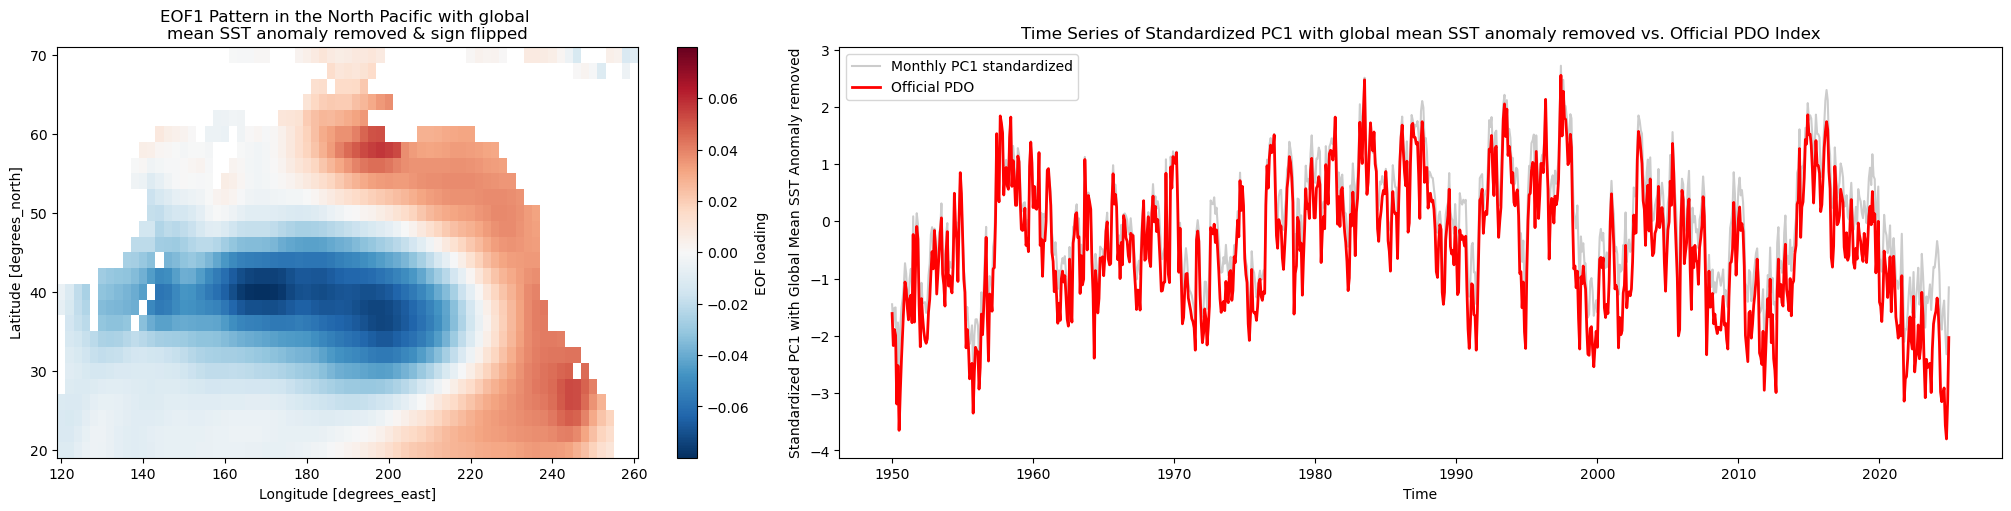

In [10]:
pca_new_pdo_eof1 = -1 * pca_new.components_[0]

pc1_new_pdo = -1 * pcs_new[:,0].flatten()
pc1_new_pdo_series = pd.Series(pc1_new_pdo, index=north_pacific_new.time.values)
pc1_new_pdo_std = pc1_new_pdo_series / pc1_new_pdo_series.std()

corr_pdo_vs_official = np.corrcoef(pc1_new_pdo, pdo_official)[0,1]
print(f"Correlation between PC1 from Q6 and the Official Index: {corr_pdo_vs_official:.3f}")

fig, axes = plt.subplots(1, 2,figsize=(20, 5), gridspec_kw={"width_ratios": [1, 2]}, layout="constrained")
to_map(pca_new_pdo_eof1, ocean_new,field=north_pacific_new).plot(ax=axes[0], cmap="RdBu_r", cbar_kwargs={"label": "EOF loading"})
axes[0].set_title("EOF1 Pattern in the North Pacific with global \nmean SST anomaly removed & sign flipped")

axes[1].plot(north_pacific_new.time, pc1_new_pdo_std, label="Monthly PC1 standardized", alpha=0.4, color="gray")
axes[1].plot(north_pacific_new.time, pdo_official, label="Official PDO", color="red", linewidth=2)

axes[1].set_title("Time Series of Standardized PC1 with global mean SST anomaly removed vs. Official PDO Index")
axes[1].set_ylabel("Standardized PC1 with Global Mean SST Anomaly removed")
axes[1].set_xlabel("Time")
axes[1].legend()

plt.show()

9) Do the same for the first-attempt PC1 from question 3, with its sign fixed the same way, and report its correlation with the official index. Which attempt matches, and by how much?

Correlation between first-attempt PC1 from Q3 and the Official Index: 0.357


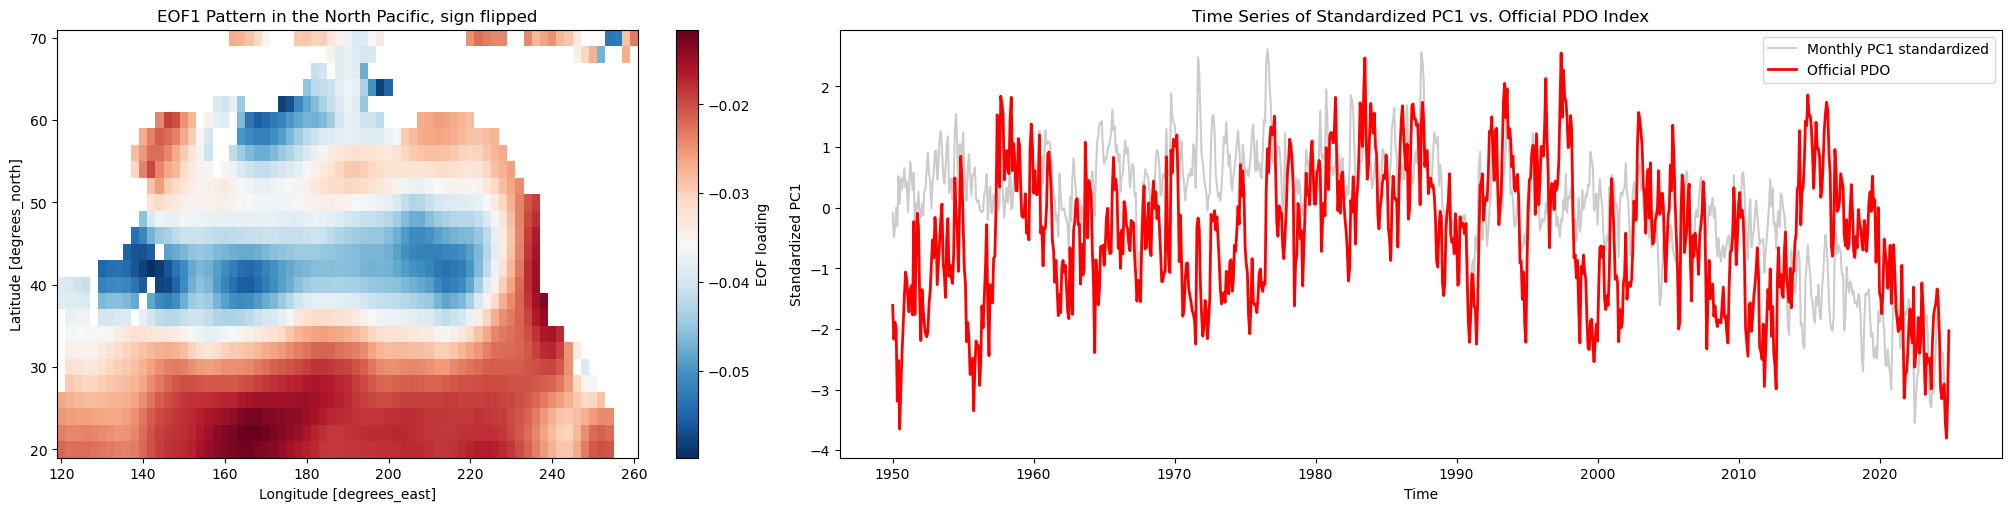

In [11]:
pca_pdo_eof1 = -1 * pca.components_[0]

pc1_pdo = -1 * pcs[:,0].flatten()
pc1_pdo_series = pd.Series(pc1_pdo, index=north_pacific.time.values)
pc1_pdo_std = pc1_pdo_series / pc1_pdo_series.std()

pc1_pdo_12month = pc1_pdo_std.rolling(window=12, center=True).mean()

corr_pdo_vs_official = np.corrcoef(pc1_pdo, pdo_official)[0,1]
print(f"Correlation between first-attempt PC1 from Q3 and the Official Index: {corr_pdo_vs_official:.3f}")

fig, axes = plt.subplots(1, 2,figsize=(20, 5), gridspec_kw={"width_ratios": [1, 2]}, layout="constrained")
to_map(pca_pdo_eof1, ocean_new,field=north_pacific).plot(ax=axes[0], cmap="RdBu_r", cbar_kwargs={"label": "EOF loading"})
axes[0].set_title("EOF1 Pattern in the North Pacific, sign flipped")

axes[1].plot(north_pacific.time, pc1_pdo_std, label="Monthly PC1 standardized", alpha=0.4, color="gray")
axes[1].plot(north_pacific.time, pdo_official, label="Official PDO", color="red", linewidth=2)

axes[1].set_title("Time Series of Standardized PC1 vs. Official PDO Index")
axes[1].set_ylabel("Standardized PC1")
axes[1].set_xlabel("Time")
axes[1].legend()

plt.show()

In [12]:
0.978-0.357

0.621

_The first-attempt PC1 is the PC1 in Q3 & Q9 and the second-attempt PC1 is the PC1 in Q6 and Q8. The second-attempt PC1 matches the Official PDO Index much better than the first-attempt PC1. The correlation between the second-attempt PC1 and the Official PDO Index (representing the pattern with the global mean removed) is 0.978, which is 0.621 higher than the correlation between first-attempt PC1 from Q3 and the Official Index of 0.357. The second attempt PC1 outperforms second attempt PC1. The background global warming trend was tainting the first attempt, masking the natural climate variability in the Pacific. Subtracting the global mean SST anomaly removes the background warming trend, allowing the second attempt to isolate the true underlying PDO pattern._

## Part 5: The PDO and ENSO

10) Compute the Niño3.4 anomaly as in the tutorial: the anomaly averaged over 5S to 5N and 190E to 240E, from the global `anom` field (not the global-mean-removed one). Make a scatter plot of your PDO index against it, one point per month, and report the correlation.

Correlation between PDO and the Niño3.4 index: 0.493
R Squared between PDO and the Niño3.4 index: 0.243
principal directions (rows), as [Niño3.4, PDO]:
[[ 0.71  0.7 ]
 [-0.7   0.71]]
fraction of variance explained: [0.746 0.254]


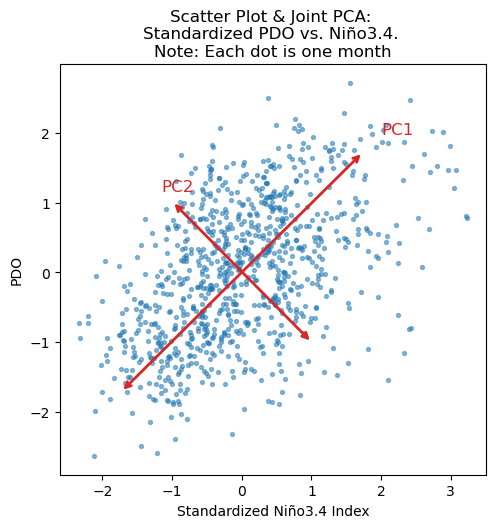

In [13]:
lat_slice = slice(-5, 5) if anom.lat[0] < anom.lat[-1] else slice(5, -5)
nino34 = anom.sel(lat=lat_slice, lon=slice(190, 240)).mean(["lat", "lon"])
nino34_index = nino34.rolling(time=5, center=True).mean()
nino34_index = nino34_index / nino34_index.std()

nino34_values = np.asarray(nino34_index.values)
pdo_values = np.asarray(pc1_new_pdo_std.values)

X2 = np.column_stack([nino34_values, pdo_values])
apply_mask = ~np.isnan(X2).any(axis=1)
X2_clean = X2[apply_mask]

corr = np.corrcoef(X2_clean[:,0],X2_clean[:,1])[0,1]
print(f"Correlation between PDO and the Niño3.4 index: {corr:.3f}")
R_squared = corr**2
print(f"R Squared between PDO and the Niño3.4 index: {R_squared:.3f}")

pca2 = PCA(n_components=2).fit(X2_clean)
print("principal directions (rows), as [Niño3.4, PDO]:")
print(np.round(pca2.components_, 2))
print("fraction of variance explained:", np.round(pca2.explained_variance_ratio_, 3))

fig, ax = plt.subplots(figsize=(5.5, 5.5))
ax.scatter(X2_clean[:, 0], X2_clean[:, 1], s=8, alpha=0.5)
for i, (vec, var) in enumerate(zip(pca2.components_, pca2.explained_variance_)):
    arrow = vec * 2 * np.sqrt(var)
    ax.annotate("", xy=pca2.mean_ + arrow, xytext=pca2.mean_ - arrow, arrowprops=dict(arrowstyle="<->", color="C3", lw=2))
    ax.text(*(pca2.mean_ + arrow * 1.15), f"PC{i + 1}", color="C3", fontsize=12)
ax.set_xlabel("Standardized Niño3.4 Index")
ax.set_ylabel("PDO")
ax.set_aspect("equal")
ax.set_title("Scatter Plot & Joint PCA: \nStandardized PDO vs. Niño3.4. \nNote: Each dot is one month")
plt.show()

11) **Written answer.** The two indices come from separate PCAs on different parts of the ocean, and yet they are correlated at about 0.5. In two or three sentences: what does that correlation tell you about the two patterns, and what does it not tell you?

_The correlation of 0.493 tells us that the two patterns are not statistically independent but rather co-vary with El Niño/La Niña events driving warm/cold PDO phases through atmospheric teleconnections, meaning that the variability in the tropics where the Niño3.4 index is measured and the variability in the North Pacific are connected. However, since the R^2 value is 0.243, only about 24% of the PDO variance can be explained by the tropical ENSO pattern, so the majority (about 76%) of the variance is driven by independent ocean and atmosphere dynamics. The correlation does not tell us which pattern drives the other (the causal relationship), and it does not tell us about the physical mechanisms linking the tropics and the North Pacific._

## Part 6: Does the pattern hold up on years it was not fitted to?

PCA was fitted on all 75 years, so the pattern has seen every month it is being compared against. The Week 6 habit is to check on data the method never saw.

12) Fit a new PCA with 10 components on the global-mean-removed matrix using only **1950 to 1990**. Project all months onto it with `transform`, fix the sign the same way as before, and report the correlation of the resulting PC1 with the official index separately for 1950 to 1990 and for 1991 to 2024.

In [14]:
X_anom_full, ocean_mask = to_matrix(north_pacific_new)
north_pac_1950_1990 = north_pacific_new.sel(time=slice("1950", "1990"))
X_anom_1950_1990, _ = to_matrix(north_pac_1950_1990)

pca_1950_1990 = PCA(n_components=10).fit(X_anom_1950_1990)

pcs_full = pca_1950_1990.transform(X_anom_full)

pc1_pdo_full = -1 * pcs_full[:,0].flatten()
pc1_pdo_series = pd.Series(pc1_pdo_full , index=north_pacific_new.time.values)
pc1_pdo_std = pc1_pdo_series / pc1_pdo_series.std()

corr_df = pd.DataFrame({"PC1": pc1_pdo_std, "Official PDO Index": pdo_official}).dropna()

corr_1950_1990 = corr_df.loc["1950":"1990", "PC1"].corr(corr_df.loc["1950":"1990", "Official PDO Index"])
corr_1991_2024 = corr_df.loc["1991":"2024", "PC1"].corr(corr_df.loc["1991":"2024", "Official PDO Index"])
print(f"Correlation (1950-1990): {corr_1950_1990:.3f}")
print(f"Correlation (1991-2024): {corr_1991_2024:.3f}")

Correlation (1950-1990): 0.960
Correlation (1991-2024): 0.972


13) **Written answer.** Why is this a fair test of the pattern, and what would it have meant if the 1991 to 2024 correlation had come out much lower than the 1950 to 1990 one?

_The 1950-1990 correlation is 0.960 and the 1991-2024 correlation is 0.972. This is a fair test of the pattern because the 1991-2024 time period is an out-of-sample validation set which lets us test whether the spatial EOF loadings from the 1950-1990 data accurately project onto future data that it was not trained on. Since the 1991-2024 correlation is very high (0.972), this tells us that the EOF pattern represents a robust physical mode of Pacific SST variability rather than being overfitted to the training period. If the 1991-2024 correlation had been significantly lower than the 1950-1990 correlation, that would imply that the historical PCA overfitted to the training period or that there was a physical change in the climate system post-1990 that impacted the Pacific SST anomalies._

## What to hand in

The notebook with all cells run, and the three written answers (questions 7, 11, and 13) in their markdown cells. Keep the written answers to a few sentences each.